# Part 1: Data Preparation and Exploratory Analysis

**Data science project: The Global Energy Transition Through Power Plants**

**Name:** Bernard Issifu

This notebook introduces the Global Power Plant Database, prepares it for analysis, and explores how
the world's generating capacity is split by fuel, how that has changed over time, and where it sits.
The same steps are implemented in R in `r/01_data_preparation_eda.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

---
# 1. The dataset

The **Global Power Plant Database** (version 1.3.0; Global Energy Observatory, Google, KTH Royal
Institute of Technology, Enipedia and World Resources Institute, 2021; CC BY 4.0) lists 34,936 power
plants in 167 countries. For each plant it records the country, name, generating **capacity** (MW),
**location** (latitude and longitude), **primary fuel** and up to three secondary fuels, the
**commissioning year** (when known), the owner and data source, reported annual generation for
2013–2019 where available, and WRI's **modelled (estimated) generation** for 2013–2017. The database is a
2021 snapshot, so plants built since then are not included.

Power plants are the core of the energy transition: replacing coal, oil and gas capacity with wind,
solar and other low-carbon sources is the largest single lever for cutting emissions.

In [2]:
raw = pd.read_csv("../data/global_power_plant_database.csv", low_memory=False)
print(raw.shape)
print(f"Countries: {raw['country_long'].nunique()}")
raw[["country_long", "name", "capacity_mw", "latitude", "longitude", "primary_fuel",
     "commissioning_year"]].head()

(34936, 36)
Countries: 167


,country_long,name,capacity_mw,latitude,longitude,primary_fuel,commissioning_year
0,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,33.0,32.322,65.1190,Hydro,NaN
1,Afghanistan,Kandahar DOG,10.0,31.670,65.7950,Solar,NaN
2,Afghanistan,Kandahar JOL,10.0,31.623,65.7920,Solar,NaN
3,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,66.0,34.556,69.4787,Hydro,NaN
4,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,100.0,34.641,69.7170,Hydro,NaN


In [3]:
fuel_counts = raw["primary_fuel"].value_counts().to_frame("plants")
fuel_counts["capacity_GW"] = raw.groupby("primary_fuel")["capacity_mw"].sum().div(1000).round(1)
fuel_counts["share_of_capacity_%"] = (fuel_counts["capacity_GW"] / fuel_counts["capacity_GW"].sum()
                                      * 100).round(1)
fuel_counts

,plants,capacity_GW,share_of_capacity_%
primary_fuel,,,
Solar,10665,188.3,3.3
Hydro,7156,1053.2,18.5
Wind,5344,263.1,4.6
Gas,3998,1493.1,26.2
Coal,2330,1965.5,34.4
Oil,2320,261.9,4.6
Biomass,1430,34.3,0.6
Waste,1068,14.7,0.3
Nuclear,195,407.9,7.1


---
# 2. Data quality

In [4]:
missing = (raw.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False).to_frame("pct_missing")
missing

,pct_missing
other_fuel3,99.7
other_fuel2,99.2
other_fuel1,94.4
generation_gwh_2013,81.6
generation_gwh_2014,79.3
generation_gwh_2015,76.5
generation_gwh_2016,73.8
generation_gwh_2017,72.8
generation_gwh_2019,72.4
generation_gwh_2018,72.4


In [5]:
# Is the commissioning year missing equally often for every fuel?
(raw.assign(year_missing=raw["commissioning_year"].isna())
    .groupby("primary_fuel")["year_missing"].mean().mul(100).round(1)
    .sort_values(ascending=False).to_frame("pct_year_missing"))

,pct_year_missing
primary_fuel,
Wave and Tidal,100.0
Solar,67.2
Biomass,59.3
Wind,57.8
Nuclear,49.7
Hydro,46.9
Waste,39.1
Other,34.9
Gas,31.3


**Interpretation.** The core fields (country, capacity, location and primary fuel) are complete.
The **commissioning year is missing for half of all plants (50.1%)**, and unevenly: about two thirds of
solar plants lack it, against about a fifth of coal plants. Reported generation is missing for 72–82% of
plants in each year, while WRI's estimated generation for 2017 is available for 95%. Secondary fuels,
owner and other identifiers are mostly missing and are not needed.

---
# 3. Preparation

Each step states what it does and why.

In [6]:
df = raw.copy()

# (1) Fuel groups: the six largest fuels keep their own label; the nine small ones (biomass, waste,
#     nuclear, geothermal, storage, cogeneration, petcoke, wave/tidal, other) become 'Other'
main_fuels = ["Solar", "Hydro", "Wind", "Gas", "Coal", "Oil"]
df["fuel"] = np.where(df["primary_fuel"].isin(main_fuels), df["primary_fuel"], "Other")

# (2) Broad category used in the trend analysis
category = {"Solar": "Renewable", "Wind": "Renewable", "Hydro": "Renewable", "Biomass": "Renewable",
            "Geothermal": "Renewable", "Wave and Tidal": "Renewable", "Coal": "Fossil",
            "Gas": "Fossil", "Oil": "Fossil", "Petcoke": "Fossil", "Cogeneration": "Fossil",
            "Nuclear": "Nuclear"}
df["category"] = df["primary_fuel"].map(category).fillna("Other")

# (3) Capacity spans 1 MW to 22,500 MW, so a log10 version is used for modelling
df["log_capacity"] = np.log10(df["capacity_mw"])

# (4) Commissioning year: half are missing, and missingness differs by fuel. The missing values are
#     filled with the overall median year, and a flag records that the year was unknown.
df["year_missing"] = df["commissioning_year"].isna().astype(int)
median_year = df["commissioning_year"].median()
df["comm_year"] = df["commissioning_year"].fillna(median_year)
print(f"Median commissioning year used for filling: {median_year:.0f}")

# (5) Whether the plant lists any secondary fuel (common for plants that can switch fuels)
df["multi_fuel"] = df["other_fuel1"].notna().astype(int)

# (6) Estimated capacity factor: WRI's estimated 2017 generation divided by the maximum possible
#     generation (capacity x 8,760 hours). Kept for the leakage check in Part 2 only, because WRI
#     estimates generation from the fuel type itself.
df["capacity_factor_est"] = (df["estimated_generation_gwh_2017"] /
                             (df["capacity_mw"] * 8.76)).clip(upper=1)

keep = ["country", "country_long", "name", "capacity_mw", "log_capacity", "latitude", "longitude",
        "primary_fuel", "fuel", "category", "commissioning_year", "comm_year", "year_missing",
        "multi_fuel", "capacity_factor_est"]
df = df[keep]
print(df.shape)
df["fuel"].value_counts().to_frame("plants")

Median commissioning year used for filling: 2007
(34936, 15)


,plants
fuel,
Solar,10665
Hydro,7156
Wind,5344
Gas,3998
Other,3123
Coal,2330
Oil,2320


---
# 4. Exploratory analysis

## 4.1 Plants and capacity by fuel

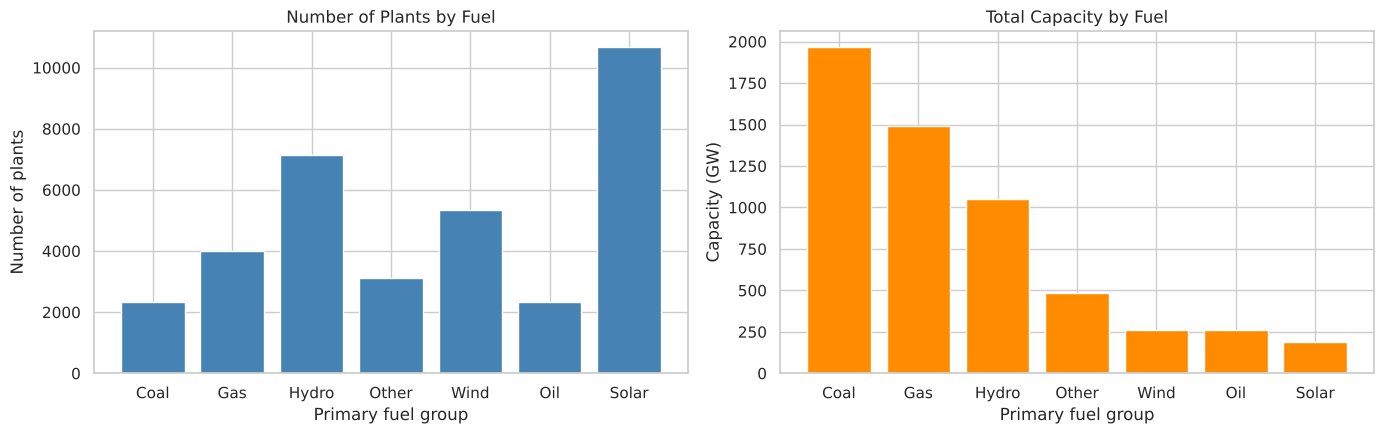

,plants,capacity_GW,median_MW
fuel,,,
Coal,2330,1965.5,600.0
Gas,3998,1493.1,147.5
Hydro,7156,1053.2,20.0
Other,3123,482.0,10.0
Wind,5344,263.1,27.0
Oil,2320,261.9,9.0
Solar,10665,188.3,5.8


In [7]:
by_fuel = df.groupby("fuel").agg(plants=("name", "size"), capacity_GW=("capacity_mw", "sum"),
                                 median_MW=("capacity_mw", "median"))
by_fuel["capacity_GW"] = (by_fuel["capacity_GW"] / 1000).round(1)
by_fuel = by_fuel.sort_values("capacity_GW", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(by_fuel.index, by_fuel["plants"], color="steelblue")
axes[0].set_title("Number of Plants by Fuel")
axes[0].set_xlabel("Primary fuel group")
axes[0].set_ylabel("Number of plants")
axes[1].bar(by_fuel.index, by_fuel["capacity_GW"], color="darkorange")
axes[1].set_title("Total Capacity by Fuel")
axes[1].set_xlabel("Primary fuel group")
axes[1].set_ylabel("Capacity (GW)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_fuel_counts_capacity.png", dpi=150)
plt.show()
by_fuel

**Interpretation.** The two charts tell opposite stories. **Solar has the most plants (10,665) but
little capacity** (188 GW, 3.3% of the total), because most solar plants are small (median 5.8 MW).
**Coal has only 2,330 plants but the largest capacity of any fuel** (1,966 GW, 34.4%), with a median
plant size of 600 MW, followed by gas (1,493 GW) and hydro (1,053 GW). Counting plants and counting megawatts give very different pictures of the
electricity system.

## 4.2 Plant size by fuel

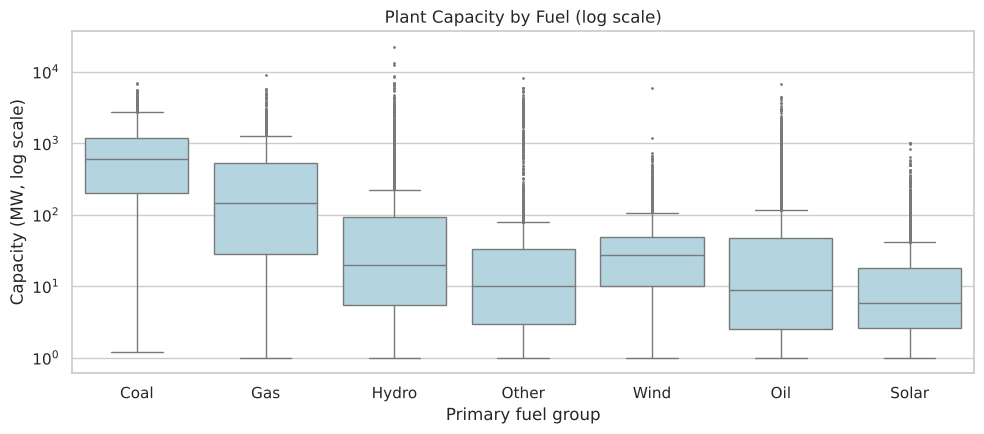

In [8]:
order = by_fuel.index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="fuel", y="capacity_mw", order=order, ax=ax, color="lightblue", fliersize=1)
ax.set_yscale("log")
ax.set_title("Plant Capacity by Fuel (log scale)")
ax.set_xlabel("Primary fuel group")
ax.set_ylabel("Capacity (MW, log scale)")
plt.tight_layout()
plt.show()

**Interpretation.** Plant sizes differ by orders of magnitude between fuels: typical coal and gas
plants are hundreds of MW, while solar and wind plants are mostly a few MW to tens of MW. Size alone
will therefore help distinguish fuels in Question 1, especially fossil versus renewable plants.

## 4.3 How the mix of new capacity has changed

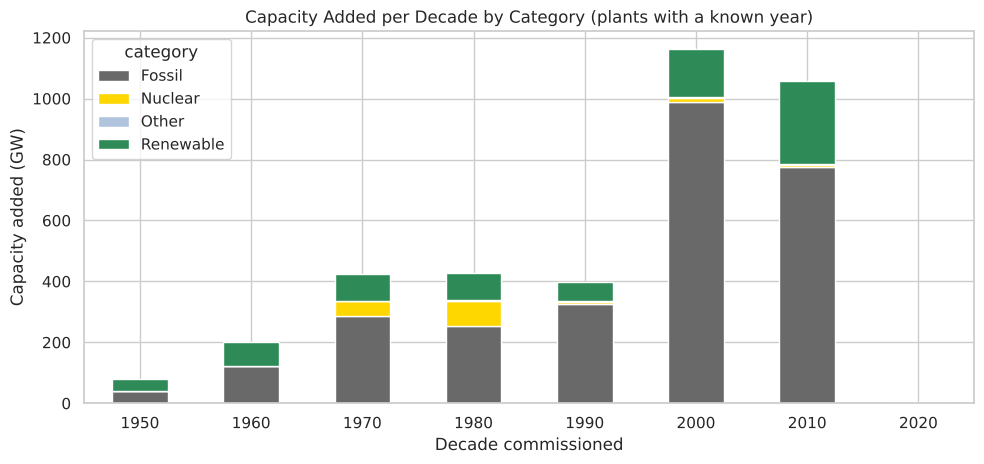

category,Fossil,Nuclear,Other,Renewable
decade,,,,
1950,52.5,0.0,0.5,46.9
1960,60.0,0.7,0.1,39.1
1970,68.0,11.2,0.1,20.7
1980,59.0,19.3,0.8,20.9
1990,82.4,1.5,0.9,15.2
2000,85.0,1.0,0.3,13.6
2010,73.3,0.5,0.3,25.8
2020,22.3,0.0,2.2,75.4


In [9]:
known = df[df["commissioning_year"].notna()].copy()
known["decade"] = (known["commissioning_year"] // 10 * 10).astype(int)
trend = (known[known["decade"] >= 1950]
         .pivot_table(index="decade", columns="category", values="capacity_mw", aggfunc="sum",
                      fill_value=0) / 1000)

ax = trend.plot(kind="bar", stacked=True, figsize=(10, 4.8),
                color={"Fossil": "dimgray", "Nuclear": "gold", "Renewable": "seagreen",
                       "Other": "lightsteelblue"})
ax.set_title("Capacity Added per Decade by Category (plants with a known year)")
ax.set_xlabel("Decade commissioned")
ax.set_ylabel("Capacity added (GW)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_capacity_by_decade.png", dpi=150)
plt.show()

share = trend.div(trend.sum(axis=1), axis=0).mul(100).round(1)
share

**Interpretation.** Among plants with a known commissioning year, **fossil fuels made up most new
capacity in every decade from the 1950s to the 2010s**, peaking at 85.0% in the 2000s, while renewables
fell from 46.9% in the 1950s (the era of large hydro dams) to 13.6% in the 2000s. The turn comes after
that: renewables' share of new capacity rose to 25.8% in the 2010s and to 75.4% for the 150 plants
commissioned in 2020, the last year in the snapshot. This is the start of the energy transition in the
data. Because half the commissioning years are missing (most often for solar and
wind), these figures understate recent renewable additions.

## 4.4 The largest countries

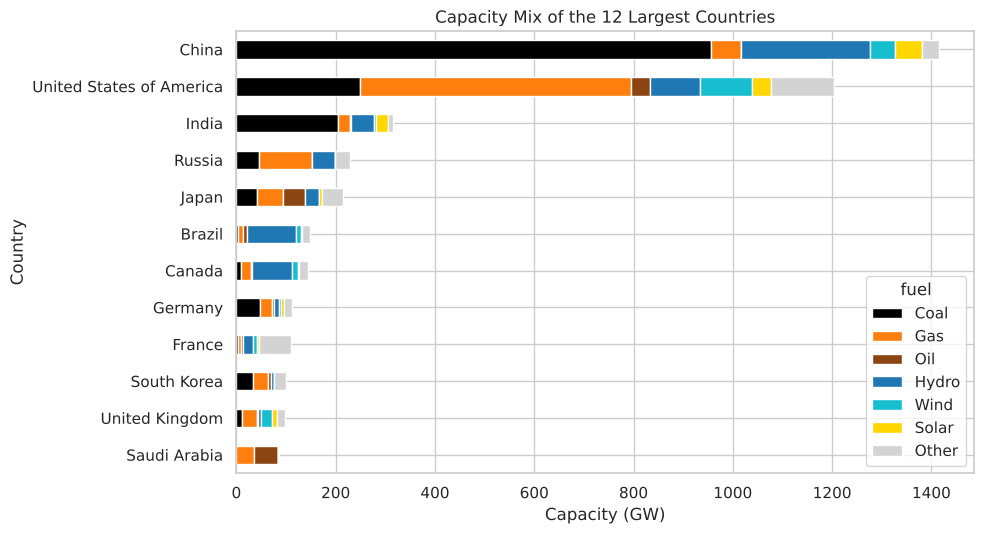

,capacity_GW
country_long,
China,1415.0
United States of America,1205.0
India,316.0
Russia,228.0
Japan,215.0
Brazil,148.0
Canada,144.0
Germany,112.0
France,111.0


In [10]:
mix = df.pivot_table(index="country_long", columns="fuel", values="capacity_mw", aggfunc="sum",
                     fill_value=0) / 1000
top = mix.loc[mix.sum(axis=1).sort_values(ascending=False).head(12).index]

ax = top[["Coal", "Gas", "Oil", "Hydro", "Wind", "Solar", "Other"]].plot(
    kind="barh", stacked=True, figsize=(10, 5.5),
    color=["black", "tab:orange", "saddlebrown", "tab:blue", "tab:cyan", "gold", "lightgray"])
ax.invert_yaxis()
ax.set_title("Capacity Mix of the 12 Largest Countries")
ax.set_xlabel("Capacity (GW)")
ax.set_ylabel("Country")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_top_countries.png", dpi=150)
plt.show()

top.sum(axis=1).round(0).to_frame("capacity_GW")

**Interpretation.** China (1,415 GW) and the United States (1,205 GW) hold by far the most capacity,
followed by India, Russia and Japan. Their mixes differ: coal is 68% of China's capacity and 65% of
India's, gas is 45% of the United States' and 47% of Russia's, hydro is 66% of Brazil's and 56% of
Canada's, and France's capacity is mostly 'Other' (58%), which here is nuclear. Question 2 groups all sizeable countries by their mix.

In [11]:
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/power_plants_clean_python.csv", index=False)
print("Saved", df.shape)

Saved (34936, 15)


---
# 5. Summary and the two project questions

The prepared data cover 34,936 plants with complete capacity, location and fuel; commissioning year is
known for half. Solar dominates by plant count, coal by capacity, and renewables' share of new
capacity has risen sharply since the 2000s.

1. **Can a plant's primary fuel be predicted from its capacity, location and commissioning year?**
   Multi-class classification (multinomial logistic regression, decision tree, random forest).
2. **Which groups of countries share similar generation mixes?** k-means clustering of countries by
   their capacity shares, compared with hierarchical clustering.